# Rutas hacia un refugio durante una inundación
## 1. Problema y objetivos
Prototipo académico: encontrar rutas válidas y comparar distancia y riesgo con BFS, Dijkstra y A*. El terreno es sintético, estático y reproducible; no sirve para decidir una evacuación real.

**Decisiones de diseño.** Matrices NumPy de 10 × 10, cuatro vecinos, costo al entrar en una celda y funciones separadas para datos, búsqueda, validación y dibujo. Cada búsqueda crea su propio estado. Ejecutar las celdas en orden desde un kernel limpio.

In [1]:
from collections import deque
from dataclasses import dataclass
import heapq
import math
from time import perf_counter
import numpy as np
from IPython.display import display, Markdown

## 2. Supuestos y representación del terreno
Coordenadas `(fila, columna)`. Códigos: 0 = seco, 1 = inundación baja, 2 = moderada, 3 = alta (intransitable), 4 = obstáculo. Solo 0, 1 y 2 permiten el paso; sus riesgos son 0, 1 y 2. Estos valores son una escala didáctica, no profundidades ni probabilidades.

Movimientos arriba, derecha, abajo e izquierda: cada uno recorre una celda. Excluir diagonales evita cortar esquinas y mantiene una sola unidad de distancia. El inicio y refugio deben ser transitables.

In [2]:
RIESGO = {0: 0, 1: 1, 2: 2}
DIRECCIONES = ((-1, 0), (0, 1), (1, 0), (0, -1))

def revisar_entrada(terreno, inicio, refugio, alfa):
    if terreno.ndim != 2 or min(terreno.shape) < 10:
        raise ValueError("El mapa debe ser una matriz de al menos 10 × 10")
    if not np.isin(terreno, [0, 1, 2, 3, 4]).all():
        raise ValueError("Código de terreno desconocido")
    if not math.isfinite(alfa) or alfa < 0:
        raise ValueError("alfa debe ser finito y no negativo")
    for p in (inicio, refugio):
        if not (0 <= p[0] < terreno.shape[0] and 0 <= p[1] < terreno.shape[1]):
            raise ValueError("Extremo fuera del mapa")
        if int(terreno[p]) not in RIESGO:
            raise ValueError("Inicio y refugio deben permitir el paso")

def vecinos(terreno, p):
    for df, dc in DIRECCIONES:
        q = (p[0] + df, p[1] + dc)
        if (0 <= q[0] < terreno.shape[0] and 0 <= q[1] < terreno.shape[1]
                and int(terreno[q]) in RIESGO):
            yield q

## 3. Modelo de riesgo y función de costo
`costo(u → v) = 1 + alfa × riesgo(v)`, con `alfa ≥ 0`. No se cobra el riesgo de la celda inicial; sí el de cada destino, incluido el refugio. Una ruta de un solo nodo tiene longitud, riesgo y costo cero.

Longitud = número de movimientos. Riesgo acumulado = suma de riesgos de las celdas visitadas después del inicio. Costo total = longitud + alfa × riesgo acumulado. Con alfa cero solo importa la distancia; valores mayores penalizan más el riesgo. No se modelan tiempo físico ni cambios del agua durante el recorrido.

In [3]:
def costo_movimiento(terreno, destino, alfa):
    return 1.0 + alfa * RIESGO[int(terreno[destino])]

def metricas(terreno, ruta, alfa):
    if ruta is None:
        return None, None, None
    longitud = len(ruta) - 1
    riesgo = sum(RIESGO[int(terreno[p])] for p in ruta[1:])
    costo = sum(costo_movimiento(terreno, p, alfa) for p in ruta[1:])
    return longitud, riesgo, costo

## 4. Implementación de los algoritmos
BFS usa una cola FIFO y minimiza movimientos, no necesariamente el costo con riesgo. Dijkstra extrae el menor costo acumulado; los costos positivos permiten cerrar cada nodo al extraerlo. A* ordena por `g + h`.

Para A*, `h = Manhattan × 1`: 1 es el costo mínimo posible de un movimiento porque alfa y riesgo no son negativos. Todo camino necesita al menos la distancia Manhattan en movimientos, por lo que h es admisible. Entre vecinos Manhattan cambia a lo sumo en 1 y cada arista cuesta al menos 1: `h(u) ≤ costo(u,v) + h(v)`, así que es consistente. Los obstáculos no invalidan estas cotas.

**Nodo expandido:** un nodo extraído válidamente de la frontera y aceptado para procesamiento, incluido el refugio aunque se termine antes de generar sus vecinos. No se cuentan entradas obsoletas del heap. Cada nodo se cuenta una vez. El desempate es determinista; no se exige que A* siempre expanda menos nodos.

In [4]:
@dataclass
class Resultado:
    ruta: object
    costo: object
    expandidos: int
    segundos: float

def reconstruir(padres, destino):
    ruta = []
    while destino is not None:
        ruta.append(destino)
        destino = padres[destino]
    return ruta[::-1]

def bfs(terreno, inicio, refugio, alfa=1.0):
    revisar_entrada(terreno, inicio, refugio, alfa)
    t0 = perf_counter()
    frontera = deque([inicio])
    padres = {inicio: None}
    expandidos = 0
    while frontera:
        actual = frontera.popleft()
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir(padres, actual)
            costo = metricas(terreno, ruta, alfa)[2]
            return Resultado(ruta, costo, expandidos, perf_counter() - t0)
        for q in vecinos(terreno, actual):
            if q not in padres:
                padres[q] = actual
                frontera.append(q)
    return Resultado(None, None, expandidos, perf_counter() - t0)

def busqueda_costo(terreno, inicio, refugio, alfa, usar_heuristica):
    revisar_entrada(terreno, inicio, refugio, alfa)
    t0 = perf_counter()
    def h(p):
        return (abs(p[0] - refugio[0]) + abs(p[1] - refugio[1])) if usar_heuristica else 0
    frontera = [(h(inicio), 0.0, inicio)]
    distancias = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    expandidos = 0
    while frontera:
        _, g, actual = heapq.heappop(frontera)
        if actual in cerrados or g != distancias[actual]:
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            return Resultado(reconstruir(padres, actual), g, expandidos, perf_counter() - t0)
        for q in vecinos(terreno, actual):
            nuevo = g + costo_movimiento(terreno, q, alfa)
            if q not in cerrados and nuevo < distancias.get(q, math.inf):
                distancias[q] = nuevo
                padres[q] = actual
                heapq.heappush(frontera, (nuevo + h(q), nuevo, q))
    return Resultado(None, None, expandidos, perf_counter() - t0)

def dijkstra(terreno, inicio, refugio, alfa=1.0):
    return busqueda_costo(terreno, inicio, refugio, alfa, False)

def a_estrella(terreno, inicio, refugio, alfa=1.0):
    return busqueda_costo(terreno, inicio, refugio, alfa, True)

ALGORITMOS = {"BFS": bfs, "Dijkstra": dijkstra, "A*": a_estrella}

## 5. Validación de rutas
El validador recalcula por su cuenta la adyacencia, transitabilidad y costo, sin usar `vecinos`, `metricas` ni `costo_movimiento`. `None` representa ausencia de solución y no un costo cero. Para resultados sin ruta se comprueba además la inaccesibilidad con un recorrido independiente de alcanzabilidad. Se compara el costo de Dijkstra y A*, no la identidad de sus rutas.

In [5]:
def validar(terreno, inicio, refugio, alfa, resultado):
    ruta = resultado.ruta
    if ruta is None:
        assert resultado.costo is None
        pendientes, vistos = [inicio], {inicio}
        while pendientes:
            f, c = pendientes.pop()
            for q in ((f-1,c), (f+1,c), (f,c-1), (f,c+1)):
                if (0 <= q[0] < terreno.shape[0] and 0 <= q[1] < terreno.shape[1]
                        and terreno[q] in (0, 1, 2) and q not in vistos):
                    vistos.add(q)
                    pendientes.append(q)
        assert refugio not in vistos, "Se reportó sin solución aunque existe ruta"
        return
    assert ruta and ruta[0] == inicio and ruta[-1] == refugio
    costo = 0.0
    for i, p in enumerate(ruta):
        assert 0 <= p[0] < terreno.shape[0] and 0 <= p[1] < terreno.shape[1]
        assert terreno[p] in (0, 1, 2)
        if i:
            anterior = ruta[i - 1]
            assert abs(p[0] - anterior[0]) + abs(p[1] - anterior[1]) == 1
            costo += 1 + alfa * int(terreno[p])
    assert math.isclose(costo, resultado.costo, rel_tol=1e-10, abs_tol=1e-10)

def comparar(terreno, inicio, refugio, alfa):
    resultados = {nombre: algoritmo(terreno, inicio, refugio, alfa)
                  for nombre, algoritmo in ALGORITMOS.items()}
    for r in resultados.values():
        validar(terreno, inicio, refugio, alfa, r)
    d, a = resultados["Dijkstra"], resultados["A*"]
    assert (d.ruta is None) == (a.ruta is None)
    if d.ruta is not None:
        assert math.isclose(d.costo, a.costo, rel_tol=1e-10, abs_tol=1e-10)
    return resultados

## 6. Escenarios y pruebas
Dos corredores conectan inicio `(5,0)` y refugio `(5,9)`. El directo tiene nueve movimientos y ocho celdas de riesgo 2; el desvío superior tiene quince movimientos secos. Para alfa = 1 sus costos son 25 y 15. Estas son predicciones del diseño, comprobadas debajo con búsquedas reales.

Las pruebas modifican copias del mapa. Se bloquea una celda interna de la ruta óptima encontrada; luego se cierra el único acceso al refugio. Para el cambio de riesgo se seca el corredor directo. La sexta prueba ejecuta A → mapa modificado → A con las mismas funciones y detecta padres, costos o nodos cerrados conservados de búsquedas anteriores. Las visualizaciones posteriores muestran los estados antes y después.

In [6]:
inicio, refugio, alfa = (5, 0), (5, 9), 1.0
base = np.full((10, 10), 4, dtype=int)
base[5, :] = 2
base[5, 0] = base[5, 9] = 0
base[2, :] = 0
base[2:6, 0] = base[2:6, 9] = 0
base[0, :3] = [0, 1, 3]  # niveles para la leyenda, sin conexión con los corredores
original = base.copy()
escenarios = {}
resultados = {}

def registrar(nombre, mapa):
    escenarios[nombre] = mapa.copy()
    resultados[nombre] = comparar(mapa, inicio, refugio, alfa)
    return resultados[nombre]

# 1. Existe ruta.
r_base = registrar("1. Base", base)
assert all(r.ruta is not None for r in r_base.values())

# 2. Bloqueo efectivo de una ruta anterior y recálculo.
celda_bloqueada = r_base["Dijkstra"].ruta[len(r_base["Dijkstra"].ruta)//2]
bloqueado = base.copy()
bloqueado[celda_bloqueada] = 4
r_bloqueado = registrar("2. Celda bloqueada", bloqueado)
for r in r_bloqueado.values():
    assert r.ruta is not None and celda_bloqueada not in r.ruta
assert r_bloqueado["Dijkstra"].costo > r_base["Dijkstra"].costo

# 3. Refugio transitable pero aislado: sus dos accesos quedan cerrados.
aislado = base.copy()
aislado[4, 9] = aislado[5, 8] = 3
r_aislado = registrar("3. Refugio aislado", aislado)
assert all(r.ruta is None and r.costo is None for r in r_aislado.values())

# 4. Cambio de riesgo sin alterar transitabilidad.
seco = base.copy()
seco[5, 1:9] = 0
r_seco = registrar("4. Región seca", seco)
assert r_seco["Dijkstra"].ruta != r_base["Dijkstra"].ruta
assert r_seco["Dijkstra"].costo == 9

# 5. Una ruta más larga cuesta menos al incorporar riesgo.
b, d = r_base["BFS"], r_base["Dijkstra"]
assert metricas(base, b.ruta, alfa) == (9, 16, 25.0)
assert metricas(base, d.ruta, alfa) == (15, 0, 15.0)
assert len(b.ruta) < len(d.ruta) and b.costo > d.costo

# 6. Regresión contra reutilización accidental del estado.
for nombre, algoritmo in ALGORITMOS.items():
    primero = algoritmo(base, inicio, refugio, alfa)
    intermedio = algoritmo(aislado, inicio, refugio, alfa)
    ultimo = algoritmo(base, inicio, refugio, alfa)
    assert intermedio.ruta is None
    assert primero.ruta == ultimo.ruta and primero.costo == ultimo.costo
    assert primero.expandidos == ultimo.expandidos
assert np.array_equal(base, original), "Una búsqueda modificó el mapa"

# Casos de borde: inicio = refugio y alfa cero.
for algoritmo in ALGORITMOS.values():
    r = algoritmo(base, inicio, inicio, alfa)
    validar(base, inicio, inicio, alfa, r)
    assert r.ruta == [inicio] and r.costo == 0
r_cero = comparar(base, inicio, refugio, 0)
assert all(r.costo == 9 for r in r_cero.values())

# El validador debe rechazar un salto y un costo reportado incorrectamente.
for malo in (Resultado([inicio, refugio], 1, 0, 0),
             Resultado(d.ruta, d.costo + 1, 0, 0)):
    try:
        validar(base, inicio, refugio, alfa, malo)
    except AssertionError:
        pass
    else:
        raise AssertionError("El validador aceptó una ruta inválida")
print("Seis pruebas obligatorias y casos adicionales: correctos.")
print("Celda bloqueada:", celda_bloqueada)

Seis pruebas obligatorias y casos adicionales: correctos.
Celda bloqueada: (2, 5)


## 7. Visualizaciones y comparación de resultados
Cada algoritmo se ejecuta una vez por escenario para esta tabla. `perf_counter()` mide la búsqueda y la construcción del resultado, excluyendo validación, dibujo y revisión de entradas. Son duraciones pequeñas y variables entre equipos y ejecuciones; no permiten afirmar superioridad temporal general. La longitud, riesgo y costo se recalculan con la misma convención. Un guion significa que no existe ruta.

In [7]:
filas = []
for escenario, rs in resultados.items():
    for nombre, r in rs.items():
        longitud, riesgo, costo = metricas(escenarios[escenario], r.ruta, alfa)
        filas.append(dict(escenario=escenario, algoritmo=nombre, encontrada=r.ruta is not None,
                          movimientos=longitud, riesgo=riesgo, costo=costo,
                          expandidos=r.expandidos, segundos=r.segundos))
tabla = ["| Escenario | Algoritmo | Ruta | Movimientos | Riesgo | Costo | Expandidos | Tiempo (ms) |",
         "|---|---|---|---:|---:|---:|---:|---:|"]
for f in filas:
    valores = [f["escenario"], f["algoritmo"], "Sí" if f["encontrada"] else "No",
               *["—" if f[k] is None else str(f[k]) for k in ("movimientos", "riesgo", "costo")],
               str(f["expandidos"]), f'{f["segundos"] * 1000:.6f}']
    tabla.append("| " + " | ".join(valores) + " |")
display(Markdown("\n".join(tabla)))

| Escenario | Algoritmo | Ruta | Movimientos | Riesgo | Costo | Expandidos | Tiempo (ms) |
|---|---|---|---:|---:|---:|---:|---:|
| 1. Base | BFS | Sí | 9 | 16 | 25.0 | 19 | 0.294300 |
| 1. Base | Dijkstra | Sí | 15 | 0 | 15.0 | 21 | 0.290800 |
| 1. Base | A* | Sí | 15 | 0 | 15.0 | 19 | 0.285100 |
| 2. Celda bloqueada | BFS | Sí | 9 | 16 | 25.0 | 17 | 0.179700 |
| 2. Celda bloqueada | Dijkstra | Sí | 9 | 16 | 25.0 | 17 | 0.234700 |
| 2. Celda bloqueada | A* | Sí | 9 | 16 | 25.0 | 17 | 0.214800 |
| 3. Refugio aislado | BFS | No | — | — | — | 21 | 0.163900 |
| 3. Refugio aislado | Dijkstra | No | — | — | — | 21 | 0.309900 |
| 3. Refugio aislado | A* | No | — | — | — | 21 | 0.262200 |
| 4. Región seca | BFS | Sí | 9 | 0 | 9.0 | 19 | 0.206700 |
| 4. Región seca | Dijkstra | Sí | 9 | 0 | 9.0 | 19 | 0.335600 |
| 4. Región seca | A* | Sí | 9 | 0 | 9.0 | 10 | 0.155000 |

Matplotlib is building the font cache; this may take a moment.


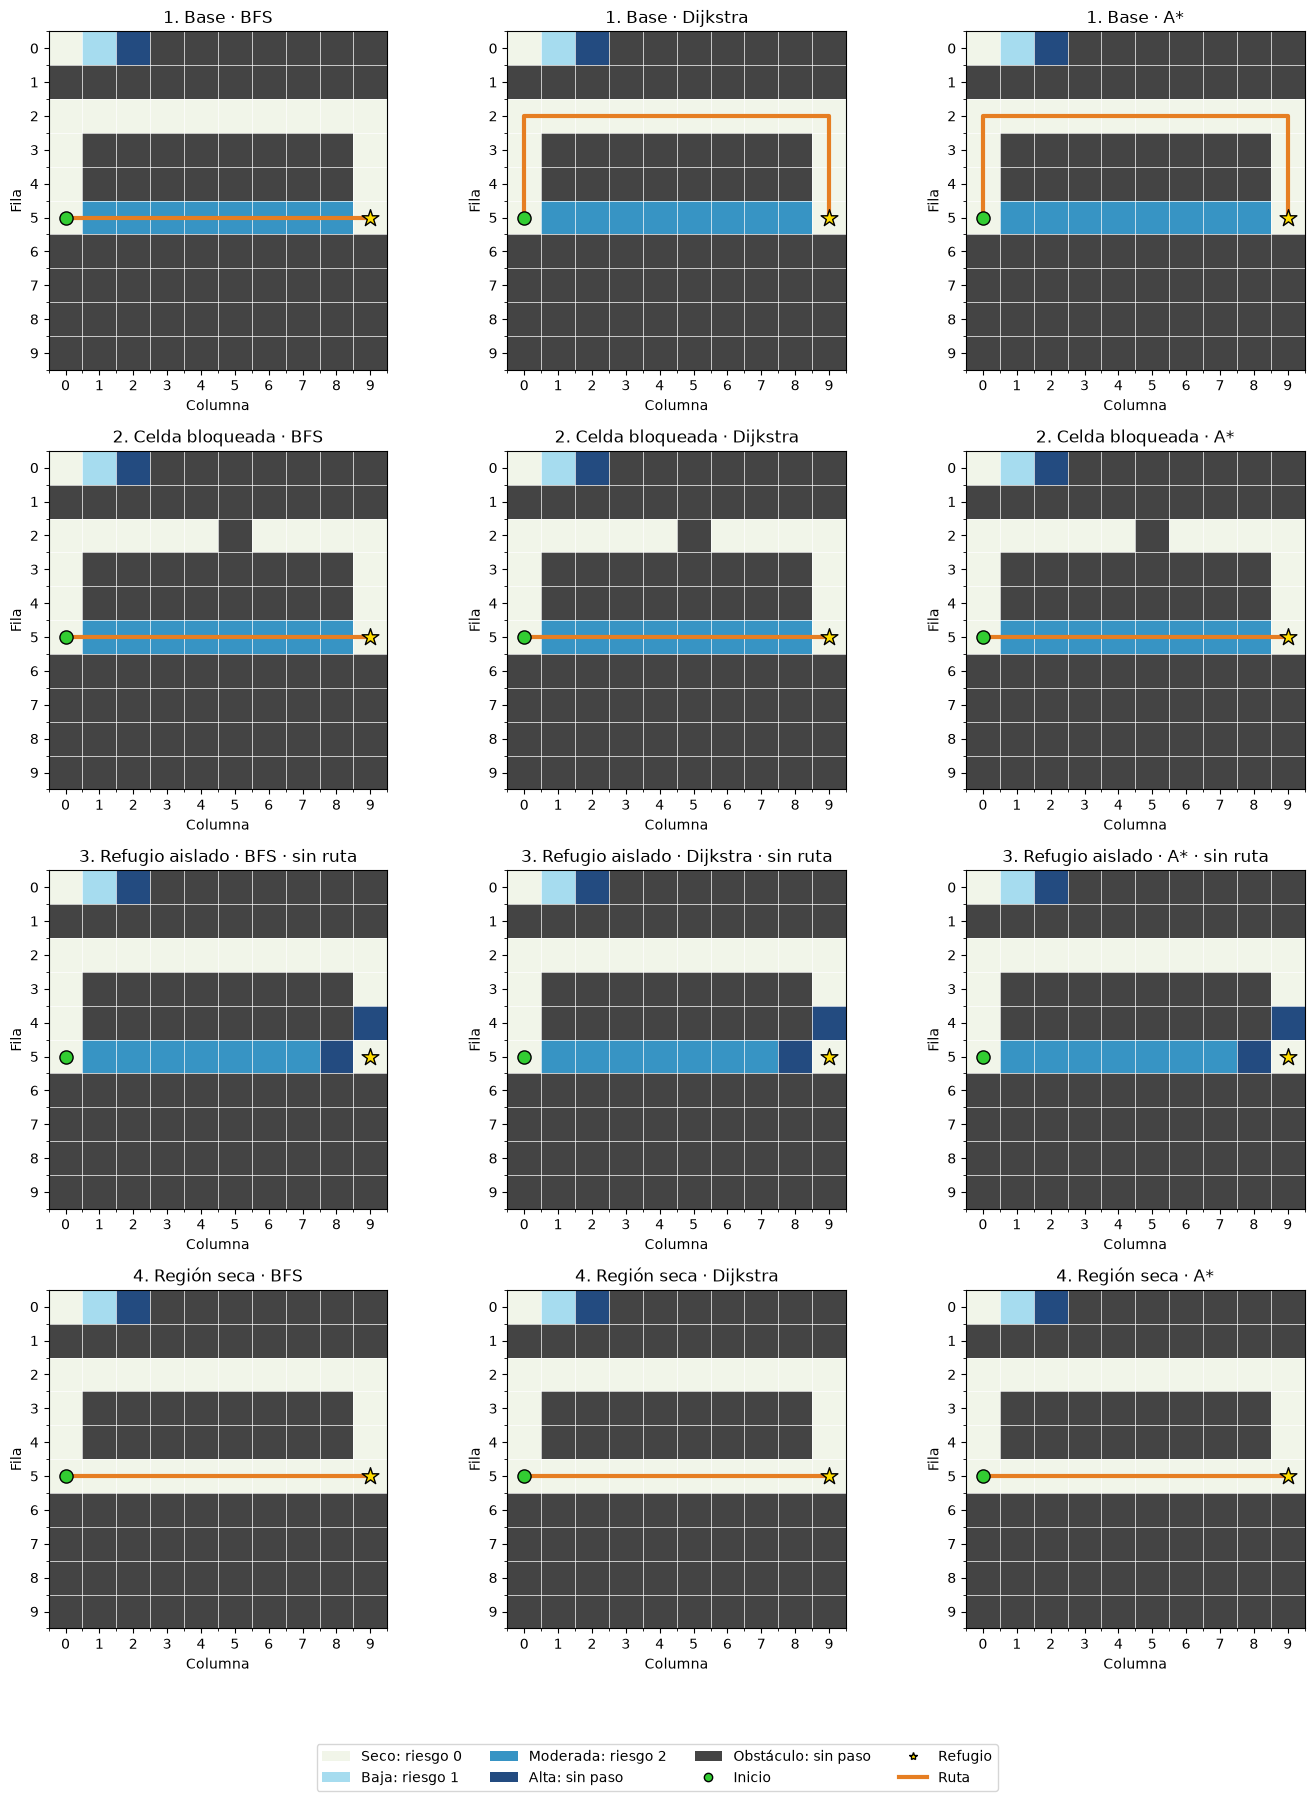

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

COLORES = ["#f1f5e9", "#a6dcef", "#3794c4", "#234b80", "#444444"]
def dibujar(ax, terreno, ruta, titulo):
    ax.imshow(terreno, cmap=ListedColormap(COLORES), norm=BoundaryNorm(np.arange(-.5, 5), 5))
    if ruta is not None:
        ax.plot([p[1] for p in ruta], [p[0] for p in ruta], color="#e67e22", lw=3)
    ax.scatter(inicio[1], inicio[0], marker="o", c="#32cd32", edgecolor="black", s=90, zorder=4)
    ax.scatter(refugio[1], refugio[0], marker="*", c="#ffdd00", edgecolor="black", s=160, zorder=4)
    ax.set(title=titulo, xlabel="Columna", ylabel="Fila", xticks=range(10), yticks=range(10))
    ax.set_xticks(np.arange(-.5, 10, 1), minor=True)
    ax.set_yticks(np.arange(-.5, 10, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=.5)

leyenda = [Patch(facecolor=c, label=t) for c, t in zip(COLORES,
           ["Seco: riesgo 0", "Baja: riesgo 1", "Moderada: riesgo 2", "Alta: sin paso", "Obstáculo: sin paso"])]
leyenda += [Line2D([], [], marker="o", color="none", markerfacecolor="#32cd32", label="Inicio"),
            Line2D([], [], marker="*", color="none", markerfacecolor="#ffdd00", label="Refugio"),
            Line2D([], [], color="#e67e22", lw=3, label="Ruta")]
fig, axes = plt.subplots(4, 3, figsize=(14, 18))
for fila, (escenario, mapa) in enumerate(escenarios.items()):
    for columna, nombre in enumerate(ALGORITMOS):
        r = resultados[escenario][nombre]
        dibujar(axes[fila, columna], mapa, r.ruta,
                f"{escenario} · {nombre}" + (" · sin ruta" if r.ruta is None else ""))
fig.legend(handles=leyenda, loc="lower center", ncol=4)
fig.tight_layout(rect=(0, .06, 1, 1))
plt.show()

### Efecto de alfa
En el mapa base, el corredor directo cuesta `9 + 16 × alfa` y el desvío seco cuesta 15. Empatan en alfa = 0.375; por encima conviene el desvío y por debajo el directo. En el empate pueden existir rutas óptimas diferentes. La siguiente celda verifica valores a ambos lados.

In [9]:
sensibilidad = []
for valor in (0, .25, .375, 1, 3):
    rs = comparar(base, inicio, refugio, valor)
    r = rs["Dijkstra"]
    longitud, riesgo, costo = metricas(base, r.ruta, valor)
    assert math.isclose(costo, min(9 + 16 * valor, 15))
    sensibilidad.append((valor, longitud, riesgo, costo))
print("alfa, movimientos, riesgo, costo")
for fila in sensibilidad:
    print(fila)

alfa, movimientos, riesgo, costo
(0, 9, 16, 9.0)
(0.25, 9, 16, 13.0)
(0.375, 15, 0, 15.0)
(1, 15, 0, 15.0)
(3, 15, 0, 15.0)


## 8. Conclusiones y limitaciones
Las aserciones y la tabla permiten verificar que en el mapa base BFS recorre 9 movimientos y acumula riesgo 16 (costo 25 para alfa = 1), mientras Dijkstra y A* encuentran costo 15 mediante 15 movimientos sin riesgo. Al bloquear el desvío, aún existe el corredor directo; al aislar el refugio los tres informan ausencia de ruta; al secar el corredor directo el costo óptimo baja a 9. Los resultados solo se consideran verificados cuando las celdas anteriores terminan sin errores.

La igualdad de costos entre Dijkstra y A* se comprueba en estos escenarios; su garantía general depende de costos no negativos y de la heurística demostrada. Ambos comparten la rutina de búsqueda de costo, por lo que esa comparación por sí sola no detectaría todos los errores compartidos: también se usan costos conocidos del diseño y un validador independiente. Los tiempos son orientativos y se conservan tal como los mide cada ejecución.

El modelo no incluye velocidad del agua, capacidad del refugio, elevación, movilidad de personas, incertidumbre ni evolución temporal. No se han validado datos geográficos ni seguridad física. Para modificarlo, cambia las matrices, extremos y alfa, y vuelve a ejecutar desde escenarios; no hace falta reescribir las búsquedas.

### Preguntas para la exposición
1. ¿Por qué BFS puede devolver una ruta más barata en distancia pero más cara en costo?
2. ¿Qué significa alfa = 0 y qué ocurre cerca de alfa = 0.375?
3. ¿Por qué no se cobra el riesgo inicial? ¿Qué cambiaría si se cobrara?
4. ¿Qué hipótesis sostienen la admisibilidad y consistencia de Manhattan?
5. ¿Cómo distingue el programa un refugio inaccesible de inicio = refugio?
6. ¿Qué error detecta ejecutar A → mapa modificado → A?
7. ¿Por qué las mediciones pequeñas no bastan para afirmar que A* siempre es más rápido?

### Uso de IA
Este prototipo y sus explicaciones fueron generados con asistencia de IA (Codex). El registro de verificación del README indica las comprobaciones realmente ejecutadas al entregar el proyecto. El equipo debe revisar, comprender y volver a ejecutar el notebook antes de atribuirse la validación; no se afirma que ya haya realizado esa revisión.